# Графики и таблицы: Matplotlib, pandas и Seaborn

Мы будем работать с погодой, велосипедными поездками, продажами напитков и товарами магазина. Все сведения учебные и вымышленные. Достаточно знать переменные, списки и вызов функций Python. Выполняйте ячейки по порядку.

В презентации и в HTML-версии каждого примера слева находится код, справа — результат, построенный именно этим кодом. В Jupyter вывод остаётся в стандартной области под ячейкой.

Следующая ячейка — служебная: она задаёт размер изображений и пути. Настройка не требует изучения нового способа построения графиков.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

# Только настройки вывода и пути к приложенным файлам.
plt.rcParams.update({
    "figure.figsize": (4.5, 3.3),
    "figure.autolayout": True,
    "font.size": 12,
    "axes.labelsize": 13,
    "legend.fontsize": 10,
})
candidates = [Path("../data"), Path("data"), Path("02_plots_pandas/data")]
DATA = next(path for path in candidates if (path / "rides.csv").exists())
OUTPUT = DATA.resolve().parent / "outputs"
OUTPUT.mkdir(exist_ok=True)

# Matplotlib: начинаем с графика

Matplotlib — библиотека Python для построения графиков. Она умеет рисовать линии, точки, столбцы и оси: нам не нужно программировать их отрисовку самим.

Начнём с модуля pyplot. Его функции работают с текущим рисунком: построить, подписать, показать. Переменные fig и ax для первых примеров не нужны.

На слайдах код находится слева, а справа — результат выполнения этого же кода. Примеры идут по порядку: созданные переменные используются дальше.

## Первый график: температура за неделю

В списке days записаны номера дней, а в temperature — температура в эти дни. Первая пара (1, 15) означает: в первый день было 15 градусов. import подключает библиотеку, as plt даёт модулю короткое имя. plot соединяет соседние точки, show показывает результат.

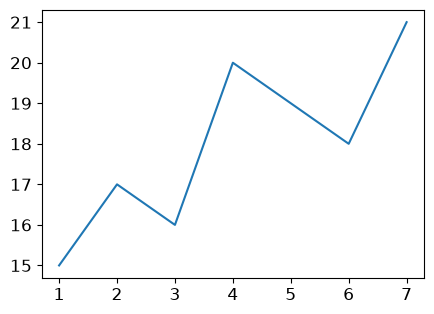

In [2]:
import matplotlib.pyplot as plt

days = [1, 2, 3, 4, 5, 6, 7]
temperature = [15, 17, 16, 20, 19, 18, 21]
plt.plot(days, temperature)
plt.show()

Первый список задаёт x, второй — y. Видно, как температура менялась по дням; но без подписей посторонний читатель ещё не знает, что означают числа.

## Добавляем смысл: оси, заголовок и точки

xlabel подписывает горизонтальную ось, ylabel — вертикальную. title задаёт заголовок, marker='o' отмечает наблюдения кружками. Все команды до show оформляют один и тот же рисунок. Подписи важны: они объясняют величины и единицы.

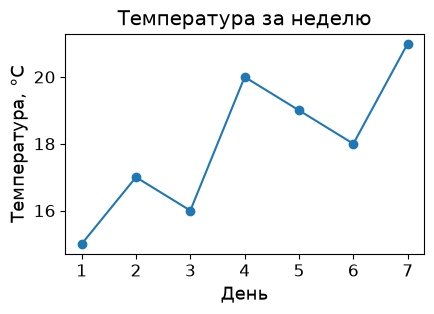

In [3]:
plt.plot(days, temperature, marker="o")
plt.xlabel("День")
plt.ylabel("Температура, °C")
plt.title("Температура за неделю")
plt.show()

Кружки — измерения, линия помогает проследить изменение между соседними днями. Попробуйте заменить температуру седьмого дня на 16 и предскажите изменение графика.

## Два города на одном рисунке

Два вызова plot до show добавляют две линии. label задаёт имя ряда, legend выводит легенду. Длина каждого списка температур равна числу дней. По легенде можно понять, какому городу соответствует линия.

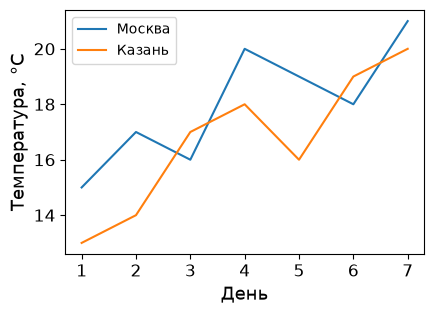

In [4]:
kazan = [13, 14, 17, 18, 16, 19, 20]
plt.plot(days, temperature,
         label="Москва")
plt.plot(days, kazan, label="Казань")
plt.xlabel("День")
plt.ylabel("Температура, °C")
plt.legend()
plt.show()

В четвёртый день в Москве 20 °C, в Казани 18 °C. Линии уместны: дни упорядочены, и соседство наблюдений имеет смысл.

## График математической функции

Для функции нужны значения аргумента и соответствующие значения функции. np.linspace создаёт 100 равномерно расположенных чисел от −2 до 2, а x ** 2 возводит каждое из них в квадрат. Много близких точек дают плавную линию.

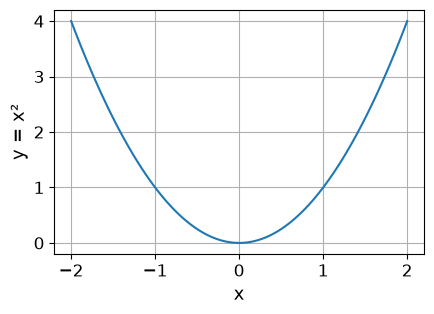

In [5]:
import numpy as np

x = np.linspace(-2, 2, 100)
plt.plot(x, x ** 2)
plt.xlabel("x")
plt.ylabel("y = x²")
plt.grid(True)
plt.show()

Это та же команда plot, но данные не измерены, а вычислены. grid добавляет сетку. Попробуйте заменить x ** 2 на np.sin(x).

## Scatter: расстояние и время поездки

Одна точка — одна поездка. distance задаёт километры, minutes — минуты той же поездки. scatter рисует точки без соединяющих отрезков: порядок поездок в списке не имеет значения. Точка (4, 18) означает четыре километра за 18 минут.

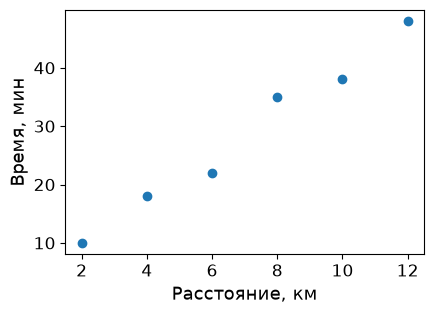

In [6]:
distance = [2, 4, 6, 8, 10, 12]
minutes = [10, 18, 22, 35, 38, 48]
plt.scatter(distance, minutes)
plt.xlabel("Расстояние, км")
plt.ylabel("Время, мин")
plt.show()

Большему расстоянию обычно соответствует большее время. Отдельные точки позволяют видеть отклонения, а не только общее направление связи.

## Bar: сравниваем продажи напитков

bar получает названия категорий и их высоты. Здесь категории — напитки, а высоты — проданные порции. Функция ничего не усредняет: она рисует переданные числа. Начало оси y в нуле позволяет честно сравнивать длины столбцов.

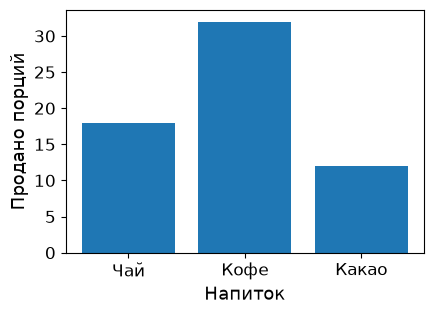

In [7]:
drinks = ["Чай", "Кофе", "Какао"]
cups = [18, 32, 12]
plt.bar(drinks, cups)
plt.xlabel("Напиток")
plt.ylabel("Продано порций")
plt.show()

Кофе продали 32 порции, чая — 18. Столбцы подходят для категорий; соединять напитки линией обычно не имеет смысла.

## Hist: как распределена скорость ветра

В гистограмму передают один список исходных наблюдений, а не готовые высоты. bins задаёт границы интервалов. hist сама считает, сколько измерений попало в каждый интервал. Порядок наблюдений в исходном списке здесь не важен.

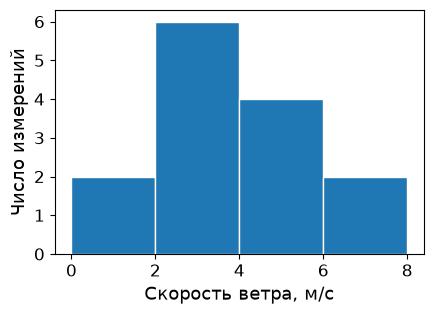

In [8]:
wind = [1, 3, 2, 5, 4, 2, 6,
        3, 1, 4, 7, 5, 2, 3]
plt.hist(wind, bins=[0, 2, 4, 6, 8],
         edgecolor="white")
plt.xlabel("Скорость ветра, м/с")
plt.ylabel("Число измерений")
plt.show()

В [2, 4) шесть измерений: три двойки и три тройки. Число 4 относится к [4, 6). Только последний интервал включает правую границу.

# Pandas: зачем хранить данные в таблице

В кафе или магазине у каждой позиции есть название, категория, цена и число продаж. Если хранить всё отдельными списками, при сортировке легко потерять связь между товаром и его ценой. Таблица хранит эти значения вместе.

pandas — библиотека Python для работы с таблицами. Она позволяет читать файлы, выбирать строки, считать по столбцам и получать сводки. Основной объект, DataFrame, — таблица с именованными столбцами. Начнём с четырёх товаров, чтобы каждый результат можно было проверить вручную.

## Создадим таблицу небольшого магазина

pd — короткое имя pandas. В словаре ключ задаёт название столбца, список — его содержимое. Значения с одной позицией попадают в одну строку. Во всех списках по четыре элемента. Одна строка описывает продажи одного товара за день.

In [9]:
import pandas as pd

table = pd.DataFrame({
    "item": ["Тетрадь", "Блокнот",
             "Ручка", "Карандаш"],
    "category": ["Бумага", "Бумага",
                 "Письмо", "Письмо"],
    "price": [80, 120, 30, 20],
    "sold": [10, 5, 20, 15],
})
table

,item,category,price,sold
0,Тетрадь,Бумага,80,10
1,Блокнот,Бумага,120,5
2,Ручка,Письмо,30,20
3,Карандаш,Письмо,20,15


pd — короткое имя pandas, ключи словаря стали названиями столбцов. Первая строка: тетрадь стоит 80 рублей, продано 10 штук. Числа 0–3 слева — индекс: метки строк, а не ещё один признак товара.

## Размер таблицы и названия столбцов

shape — свойство таблицы, оно возвращает пару: число строк и число столбцов. len(table) сообщает только число строк. columns содержит названия столбцов; tolist превращает их в обычный список. print нужен, чтобы показать несколько результатов в одной ячейке.

In [10]:
print(table.shape)
print(len(table))
print(table.columns.tolist())

(4, 4)
4
['item', 'category', 'price', 'sold']


Получили четыре строки и четыре столбца. Эти команды только смотрят на таблицу и ничего из неё не удаляют.

## Выбираем один столбец

Квадратные скобки с названием выбирают столбец. Получится Series — одномерный объект со значениями и индексом. Слева сохраняются метки исходных строк. DataFrame — вся таблица, Series — один её столбец.

In [11]:
prices = table["price"]
prices

0     80
1    120
2     30
3     20
Name: price, dtype: int64

Справа показаны индекс и значения выбранной Series. В Jupyter дополнительно появляется строка Name: price, dtype: int64 — имя столбца и тип его значений.

## Вычисляем по столбцу

Метод mean считает среднее, min — минимум, max — максимум, sum — сумму. Точка в prices.mean() означает вызов метода у выбранного столбца. Скобки нужны, потому что мы просим выполнить действие.

In [12]:
print("Средняя цена:", prices.mean())
print("Минимум:", prices.min())
print("Максимум:", prices.max())
print("Всего продано:",
      table["sold"].sum())

Средняя цена: 62.5
Минимум: 20
Максимум: 120
Всего продано: 50


Средняя цена: (80 + 120 + 30 + 20) / 4 = 62.5 рубля. Средняя цена товара здесь не взвешена по числу продаж.

## Выбираем несколько столбцов

Внутренние скобки создают список названий, внешние выбирают эти столбцы. Результат — новая таблица с двумя столбцами. Исходная table остаётся прежней.

In [13]:
table[["item", "sold"]]

,item,sold
0,Тетрадь,10
1,Блокнот,5
2,Ручка,20
3,Карандаш,15


Теперь удобно смотреть только названия и количество продаж. Попробуйте вместо sold выбрать price и объяснить, что изменится.

## Условие сначала даёт ответы True или False

Выберем товары с ценой не меньше 80 рублей. Сравнение со столбцом выполняется для каждой строки отдельно. Результат — булева маска: подходит ли эта строка под условие. Пока мы ничего не отбирали, а только вычислили ответы.

In [14]:
mask = table["price"] >= 80
mask

0     True
1     True
2    False
3    False
Name: price, dtype: bool

Тетрадь и блокнот подходят: напротив них True. Ручка и карандаш не подходят: напротив них False.

## Используем маску для отбора строк

Передадим маску в квадратные скобки таблицы. pandas оставит только строки, в которых mask равна True. Все значения одной строки останутся вместе. Можно и сразу записать table[table['price'] >= 80], без промежуточной переменной.

In [15]:
expensive = table[mask]
expensive

,item,category,price,sold
0,Тетрадь,Бумага,80,10
1,Блокнот,Бумага,120,5


Остались два товара, а не два отдельных числа. Индексы сохранились из исходной таблицы. Попробуйте отобрать товары, которых продано больше 10 штук.

## Два условия одновременно

Сравнение текста устроено так же, как сравнение чисел. Двойное равенство проверяет совпадение значения. Знак & означает «и»: нужны обе истины сразу. Каждое сравнение заключаем в собственные скобки.

In [16]:
mask = ((table["category"] == "Письмо")
        & (table["sold"] >= 18))
table[mask]

,item,category,price,sold
2,Ручка,Письмо,30,20


В категории «Письмо» два товара, но не меньше 18 штук продано только ручек. Подходящая строка одна, и её индекс по-прежнему 2.

## Упорядочим товары по продажам

sort_values сортирует по значениям указанного столбца. ascending=False означает от большего к меньшему. Перемещается строка целиком, поэтому название товара не теряет связь с ценой. Результат сохраняем в другой переменной.

In [17]:
popular = table.sort_values(
    "sold", ascending=False
)
popular

,item,category,price,sold
2,Ручка,Письмо,30,20
3,Карандаш,Письмо,20,15
0,Тетрадь,Бумага,80,10
1,Блокнот,Бумага,120,5


Первыми идут ручки: продано 20 штук. Исходная table не меняет порядок. popular.head(2) покажет два наиболее продаваемых товара.

## Новый столбец: выручка по каждому товару

Умножение двух столбцов выполняется построчно. Для тетрадей 80 × 10 = 800 рублей. Не нужно писать цикл. Слева от знака = укажем новое название: pandas добавит столбец в таблицу.

In [18]:
table["revenue"] = (
    table["price"] * table["sold"]
)
table[["item", "revenue"]]

,item,revenue
0,Тетрадь,800
1,Блокнот,600
2,Ручка,600
3,Карандаш,300


Это выручка, не прибыль: расходы нам неизвестны. Справа для наглядности выведены только название и новый столбец.

## Groupby: отдельная сумма для каждой категории

Нам нужна не общая сумма магазина, а сумма по каждой категории. groupby разделяет строки по category, затем мы берём revenue и применяем sum отдельно в каждой группе. Для бумаги это 800 + 600, для письменных принадлежностей — 600 + 300.

In [19]:
groups = table.groupby("category")
revenue_by_category = (
    groups["revenue"].sum()
)
revenue_by_category

category
Бумага    1400
Письмо     900
Name: revenue, dtype: int64

В результате индекс — названия категорий, значения — их выручка. Получились 1400 и 900 рублей. Сам groupby ещё не считает: действие задаёт sum.

## Покажем готовую сводку на графике

У полученной Series .index содержит названия категорий, .values — суммы. Передадим их в уже знакомый bar. Здесь ничего нового в построении не появилось: вместо вручную написанных списков мы используем результат вычисления.

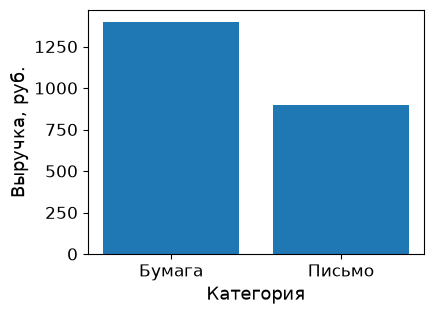

In [20]:
plt.bar(revenue_by_category.index,
        revenue_by_category.values)
plt.xlabel("Категория")
plt.ylabel("Выручка, руб.")
plt.show()

Высота столбца — выручка категории, а не количество товаров. Подпись оси y помогает не перепутать смысл агрегированных чисел.

# Pandas: читаем данные о поездках

Таблицу не обязательно создавать вручную. CSV — текстовый формат, где строки соответствуют наблюдениям, а значения разделены запятыми. Первая строка задаёт названия столбцов. read_csv превращает такой файл в обычный DataFrame.

В приложенном rides.csv одна строка — одна поездка на велосипеде. trip_id — номер, bike — тип велосипеда, distance_km — километры, minutes — время. Данные синтетические и не описывают реальных людей. После загрузки работают те же столбцы, маски и группировки, что и в маленьком примере магазина.

## Загрузим файл и посмотрим начало

DATA — путь к папке с приложенными файлами. Он настроен в служебной ячейке ноутбука; знак / соединяет папку и имя файла. head(4) показывает первые четыре строки, не удаляя остальные. В правой части видны именно строки прочитанного файла.

In [21]:
raw = pd.read_csv(DATA / "rides.csv")
raw.head(4)

,trip_id,bike,distance_km,minutes
0,1,Городской,14.0,58.9
1,2,Горный,15.8,78.8
2,3,Шоссейный,23.1,72.1
3,4,Городской,23.3,98.5


Одна поездка имеет и расстояние, и время, и тип велосипеда. Первые строки полезно прочитать словами перед тем, как считать статистики.

## Размер и неизвестные значения

shape сообщает размер, isna проверяет каждую ячейку на пропуск. sum считает число True по каждому столбцу. Пропущенная длительность — не нулевая поездка: мы просто не знаем, сколько она длилась.

In [22]:
print("Размер:", raw.shape)
print("Пропуски:")
print(raw.isna().sum())

Размер: (61, 4)
Пропуски:
trip_id        0
bike           0
distance_km    2
minutes        3
dtype: int64


Всего 61 строка. Не записаны два расстояния и три длительности. Заменять их нулём означало бы придумать сведения, которых нет.

## Удалим технический повтор и подготовим пары

В описании этого учебного файла указано: одна запись случайно продублирована. drop_duplicates оставляет первое вхождение каждой строки. Для scatterplot нужны оба числовых признака; dropna(subset=...) убирает строки с пропуском в них.

In [23]:
clean = raw.drop_duplicates().copy()
trips = clean.dropna(
    subset=["distance_km", "minutes"]
)
print("Без повторов:", len(clean))
print("Полных пар:", len(trips))

Без повторов: 60
Полных пар: 55


Осталось 60 разных поездок и 55 полных пар. В других наборах одинаковые строки могут быть разными событиями: удалять повторы без понимания их смысла нельзя.

## Столбцы вместо списков в Matplotlib

Передадим два столбца одной таблицы в scatter. Координаты по-прежнему относятся к одной поездке, потому что строки не разъединялись. alpha уменьшает непрозрачность: перекрывающиеся точки легче различить.

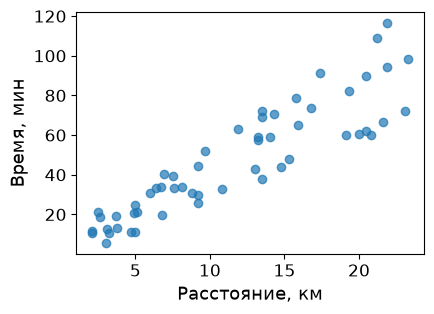

In [24]:
plt.scatter(trips["distance_km"],
            trips["minutes"], alpha=0.7)
plt.xlabel("Расстояние, км")
plt.ylabel("Время, мин")
plt.show()

На рисунке 55 точек. Часть разброса связана с разной скоростью велосипедов: одного расстояния недостаточно, чтобы точно предсказать время.

# Seaborn: связываем график с таблицей

Seaborn — библиотека поверх Matplotlib, которая упрощает распространённые графики анализа данных. Ей можно передать всю таблицу и назвать столбцы для x, y и цвета. Она сама найдёт категории, назначит цвета и создаст легенду.

Сначала построим ту же диаграмму рассеяния. Затем добавим информацию о типе велосипеда. Подписи через plt продолжат работать: основой рисунка остаётся Matplotlib. Переменная ax и здесь не обязательна.

## Тот же график через Seaborn

data указывает таблицу, а x и y содержат названия её столбцов. Это не отдельные переменные Python. Поменялся способ указать данные, но не смысл графика: одна точка по-прежнему означает одну поездку.

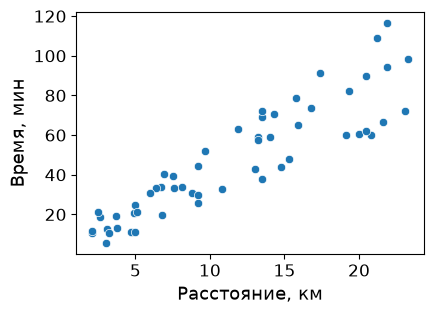

In [25]:
import seaborn as sns

sns.scatterplot(data=trips,
    x="distance_km", y="minutes")
plt.xlabel("Расстояние, км")
plt.ylabel("Время, мин")
plt.show()

Координаты совпадают с предыдущим примером. Seaborn не добавляет новые поездки и не усредняет данные в scatterplot.

## Цвет показывает тип велосипеда

hue связывает цвет точки со значением ещё одного столбца той же строки. Мы указываем bike, а Seaborn сам находит три типа велосипеда. Так на одном рисунке видны сразу расстояние, время и категория.

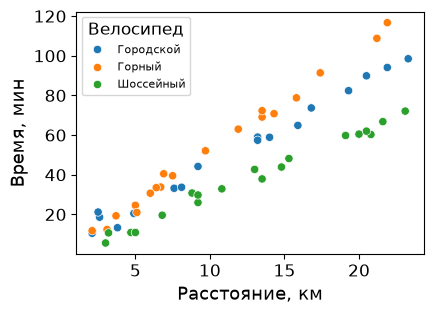

In [26]:
sns.scatterplot(data=trips,
    x="distance_km", y="minutes",
    hue="bike")
plt.xlabel("Расстояние, км")
plt.ylabel("Время, мин")
plt.legend(title="Велосипед", fontsize=8)
plt.show()

hue="bike" задаёт цвет по типу велосипеда и создаёт легенду. Разные скорости здесь заложены в генераторе: это учебная модель, а не реальное измерение преимуществ велосипеда.

## Посмотрим на отдельные поездки в категориях

stripplot размещает числовые значения по категориям. jitter слегка раздвигает точки по горизонтали, чтобы близкие значения было легче увидеть. Горизонтальное смещение не означает ещё один измеренный признак.

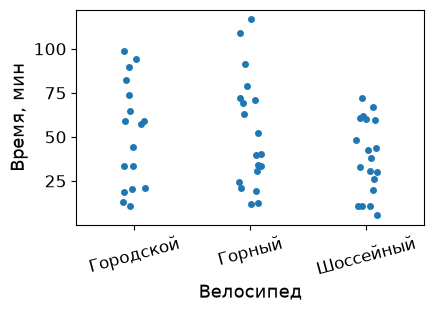

In [27]:
np.random.seed(1514)
sns.stripplot(data=trips,
    x="bike", y="minutes", jitter=True)
plt.xlabel("Велосипед")
plt.ylabel("Время, мин")
plt.xticks(rotation=15)
plt.show()

seed фиксирует случайное горизонтальное смещение точек. Время внутри категории различается, ведь расстояния тоже разные. Сравнивать скорость только по этому рисунку было бы неправильно.

# Встроенные графики pandas

После Matplotlib и Seaborn познакомимся ещё с одной записью: Series.plot() и DataFrame.plot(). Эти методы позволяют построить распространённый график прямо из столбца или таблицы. По умолчанию pandas использует Matplotlib, поэтому знакомые подписи и сохранение через plt продолжают работать.

kind задаёт тип: bar — столбцы, hist — гистограмма, scatter — точки, line — линии. Для Series подписи часто берутся из индекса, значения — из содержимого столбца. Для DataFrame мы явно укажем x и y. Создавать fig и ax для этих примеров не нужно.

## Series.plot: готовая выручка в виде столбцов

Вернёмся к сводке магазина. Её индекс уже содержит категории, а значения — суммы. Метод plot(kind='bar') использует их автоматически: отдельно доставать index и values не требуется. Средние или суммы внутри bar заново не вычисляются.

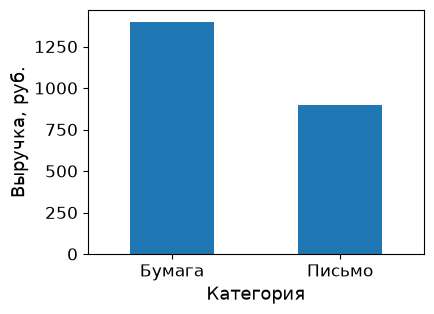

In [28]:
revenue_by_category.plot(
    kind="bar", rot=0
)
plt.xlabel("Категория")
plt.ylabel("Выручка, руб.")
plt.show()

Это тот же результат, что у plt.bar для сводки: 1400 и 900 рублей. rot=0 оставляет подписи горизонтальными; отдельный plt.figure не нужен.

## Гистограмма столбца из другого CSV

В weather.csv записана вымышленная погода за две недели: день, температуры Москвы и Казани, скорость ветра. Выберем температуру Москвы и попросим Series построить гистограмму. Теперь передаём исходные температуры, а не готовые частоты.

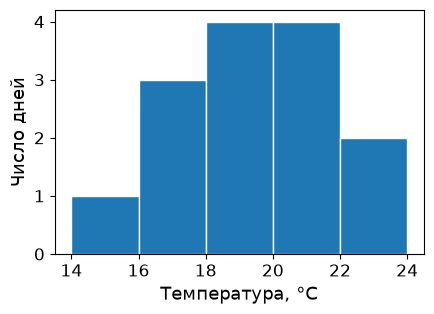

In [29]:
weather = pd.read_csv(
    DATA / "weather.csv"
)
weather["moscow"].plot(
    kind="hist",
    bins=[14, 16, 18, 20, 22, 24],
    edgecolor="white"
)
plt.xlabel("Температура, °C")
plt.ylabel("Число дней")
plt.show()

Всего 14 наблюдений. Высота прямоугольника сообщает, сколько дней температура лежала в данном интервале, а не в какой день она наблюдалась.

## DataFrame.plot: явно выбираем два столбца

Диаграмма рассеяния требует двух признаков, поэтому plot вызывается у DataFrame. Таблица уже указана слева от точки, параметр data не нужен. Имена x и y читаются как названия столбцов этой таблицы.

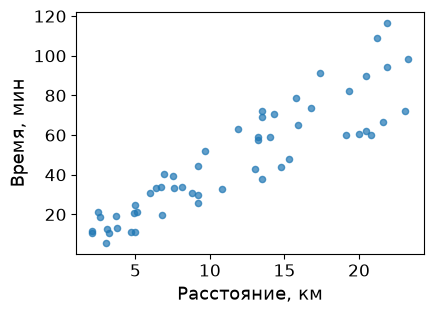

In [30]:
trips.plot(kind="scatter",
    x="distance_km", y="minutes",
    alpha=0.7)
plt.xlabel("Расстояние, км")
plt.ylabel("Время, мин")
plt.show()

Снова те же 55 пар. Для быстрого графика этого достаточно; для удобного цвета по категориям можно вернуться к Seaborn и hue.

## Несколько линий из столбцов таблицы

По оси x выберем day, а в y передадим список из двух температурных столбцов. pandas нарисует обе линии и создаст легенду из их названий. Линии осмысленны: дни идут по порядку.

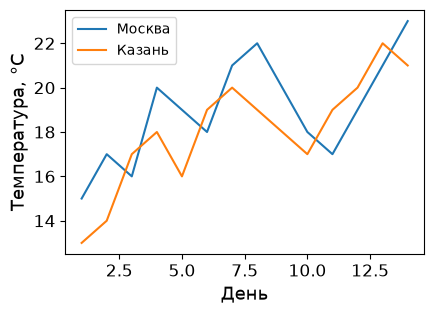

In [31]:
weather.plot(x="day",
    y=["moscow", "kazan"], kind="line")
plt.xlabel("День")
plt.ylabel("Температура, °C")
plt.legend(["Москва", "Казань"])
plt.show()

Без kind по умолчанию тоже получились бы линии. Можно писать и сокращения: .plot.bar(), .plot.hist(), .plot.scatter(x=..., y=...).

# Сохранение и самостоятельная работа

Теперь мы умеем брать сведения из списка, таблицы или файла и выбирать график по вопросу. Линия показывает изменение по упорядоченному аргументу; точки — связь двух чисел; столбцы — значения категорий; гистограмма — распределение.

pandas готовит данные и сводки, Seaborn помогает связывать визуальные свойства со столбцами, Matplotlib управляет самим рисунком. Способы можно сочетать: начать через pandas, а подписи и сохранение добавить через plt.

## Сохраним таблицу и прочитаем обратно

У сводки названия категорий находятся в индексе. reset_index превращает их в обычный столбец, name задаёт название столбца со значениями. to_csv записывает файл; index=False не добавляет к данным ещё один столбец с номерами строк.

In [32]:
summary = revenue_by_category.reset_index(
    name="revenue"
)
summary.to_csv(
    OUTPUT / "sales_summary.csv",
    index=False)
pd.read_csv(OUTPUT / "sales_summary.csv")

,category,revenue
0,Бумага,1400
1,Письмо,900


Справа — результат обратного чтения сохранённого файла, а не вручную набранная копия. Папка OUTPUT настроена в начале ноутбука.

## Сохранение рисунка не меняет его смысл

savefig вызывается после построения и подписей, но до show. Расширение имени задаёт формат: PNG для растровой картинки, PDF для векторной вставки в презентацию. dpi задаёт разрешение PNG; bbox_inches уменьшает лишние поля.

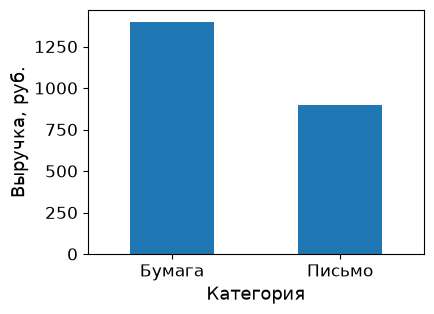

In [33]:
revenue_by_category.plot(
    kind="bar", rot=0)
plt.xlabel("Категория")
plt.ylabel("Выручка, руб.")
plt.savefig(OUTPUT / "sales.png", dpi=150,
            bbox_inches="tight")
plt.show()

Справа тот же рисунок, который записан в sales.png. Перед публикацией проверьте подписи, единицы измерения и смысл каждой высоты.

# Дополнительно: несколько областей рисунка

Для одного рисунка достаточно разобранных команд plt. Если нужны две независимые области рядом, удобно получить явные переменные. fig обозначает весь рисунок, axes[0] и axes[1] — его области.

Это дополнительный способ управления, а не обязательный шаг перед каждым графиком. Методы областей похожи на знакомые функции: axes[0].hist вместо plt.hist, set_xlabel вместо xlabel.

## Два вопроса на одном рисунке

subplots(1, 2) создаёт одну строку из двух областей. В первой посмотрим распределение расстояний поездок, во второй — связь расстояния с длительностью. Каждой области можно независимо задать подписи и масштаб.

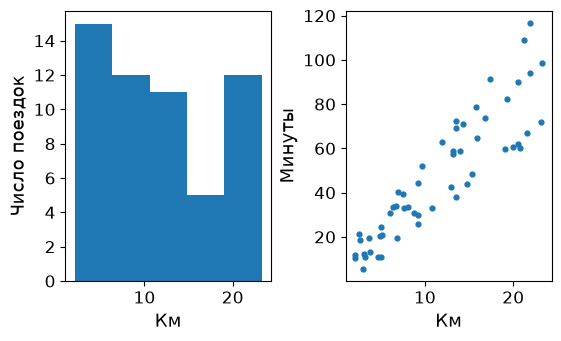

In [34]:
fig, axes = plt.subplots(
    1, 2, figsize=(5.5, 3.3),
    layout="constrained")
axes[0].hist(trips["distance_km"], bins=5)
axes[0].set_xlabel("Км")
axes[0].set_ylabel("Число поездок")
axes[1].scatter(trips["distance_km"],
                trips["minutes"], s=12)
axes[1].set_xlabel("Км")
axes[1].set_ylabel("Минуты")
plt.show()

Здесь переменные областей действительно полезны: понятно, куда направлена каждая команда. В обязательном ДЗ этот интерфейс не требуется.